# Following the Fluid

**Lagrangian coordinates, Burgers' equation and Cole–Hopf, worked by hand in $(x,t)$, then applied
to blood, respiratory droplets, special relativity and light. Solved in NumPy, CUDA, MATLAB and torch.**

Navier–Stokes in 3D is hard. Its one-dimensional skeleton, **Burgers' equation**, keeps the two terms
that fight each other: nonlinear steepening $u\,u_x$ and viscous smoothing $\nu u_{xx}$. Burgers has
two properties that make it the right place to learn the ideas before going back to 3D:

* In **Lagrangian coordinates** (following each fluid particle) the inviscid equation is solved by
  straight lines, and you can watch the gradient blow up in finite time.
* The **Cole–Hopf** substitution turns the nonlinear equation into the linear, homogeneous heat
  equation, so we have an *exact* solution to test every code against.

| § | topic | what is verified |
|---|---|---|
| 1 | Griffiths check: momentum conservation | SymPy identity |
| 2 | Hand derivation in $(x,t)$: Burgers → heat equation | SymPy identity |
| 3 | Lagrangian coordinates, characteristics, breaking time | SymPy + exact solution |
| 4 | Special relativity: $u^\mu\partial_\mu$ is the material derivative | SymPy identity |
| 5 | Light as a fluid (Madelung), the "nature as a computer" idea | SymPy identity |
| 6 | Blood vs water: Reynolds and Womersley numbers | ODE residual, Poiseuille limit |
| 7 | Respiratory droplets: Stokes settling | SymPy force balance |
| 8 | NumPy, torch (CUDA/CPU), CUDA C, MATLAB vs exact | max error, throughput |

**Scope.** The physiological and aerosol numbers are textbook-typical values for a physics exercise.
They are **not** medical or public-health guidance. The Metal (Apple GPU) path is the standard
torch `mps` device and is **untested** here, because this machine runs Windows with an NVIDIA GPU.

Module: [`dgs/lagrangian_fluids.py`](../dgs/lagrangian_fluids.py)

**References (IEEE)**
1. D. J. Griffiths, *Introduction to Electrodynamics*, 5th ed. Cambridge, U.K.: Cambridge Univ. Press, 2023, ch. 8.
2. J. M. Burgers, "A mathematical model illustrating the theory of turbulence," *Adv. Appl. Mech.*, vol. 1, pp. 171–199, 1948.
3. E. Hopf, "The partial differential equation $u_t + uu_x = \mu u_{xx}$," *Commun. Pure Appl. Math.*, vol. 3, no. 3, pp. 201–230, 1950.
4. J. D. Cole, "On a quasi-linear parabolic equation occurring in aerodynamics," *Q. Appl. Math.*, vol. 9, no. 3, pp. 225–236, 1951.
5. J. R. Womersley, "Method for the calculation of velocity, rate of flow and viscous drag in arteries when the pressure gradient is known," *J. Physiol.*, vol. 127, no. 3, pp. 553–563, 1955.
6. W. F. Wells, "On air-borne infection. Study II. Droplets and droplet nuclei," *Am. J. Hygiene*, vol. 20, pp. 611–618, 1934.
7. E. Madelung, "Quantentheorie in hydrodynamischer Form," *Z. Phys.*, vol. 40, pp. 322–326, 1927.
8. B. Jalali, A. Kadambi, and V. Roychowdhury, "Physics-AI symbiosis," arXiv:2109.05959, 2021.

In [1]:
import sys, pathlib, shutil, subprocess
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs import lagrangian_fluids as L
from dgs.lagrangian_fluids import x, t, X, nu
print(sys.version.split()[0])

3.12.7


# 1. Griffiths check: momentum conservation always has one shape

Griffiths §8.2 writes electromagnetic momentum conservation as
$$\frac{\partial \mathbf g}{\partial t} = \nabla\cdot\overleftrightarrow{\mathbf T} - \mathbf f, \qquad \mathbf g = \epsilon_0\mu_0\,\mathbf S,$$
momentum density changing because of a stress tensor's divergence and the force on charges. A fluid
says exactly the same thing. In 1D the momentum density is $\rho u$ and the momentum flux is
$\rho u^2 + p - \mu u_x$ (carried momentum + pressure + viscous stress):
$$(\rho u)_t + (\rho u^2 + p - \mu u_x)_x = 0 .$$
Subtracting $u\times$(continuity) leaves Newton's law per unit volume, $\rho\,Du/Dt = -p_x + \mu u_{xx}$.
SymPy checks that the conservative form, minus Newton's law, minus $u\times$continuity, is identically zero:

In [2]:
print("conservative - Newton - u*continuity =", L.momentum_conservation_identity())

conservative - Newton - u*continuity = 0


| | electromagnetism (Griffiths 8.2) | fluid |
|---|---|---|
| momentum density | $\mathbf g = \epsilon_0 \mathbf E\times\mathbf B$ | $\rho\mathbf u$ |
| stress tensor | Maxwell $T_{ij}$ | $-\rho u_iu_j - p\,\delta_{ij} + \mu(\partial_iu_j+\partial_ju_i)$ |
| conservation law | $\partial_t\mathbf g = \nabla\cdot T - \mathbf f$ | $\partial_t(\rho\mathbf u) = \nabla\cdot\sigma + \mathbf f$ |

Navier–Stokes is just this conservation law plus one constitutive choice: stress proportional to strain
rate (Newtonian fluid). Blood breaks that choice (§6).

# 2. The hand derivation in $(x, t)$: Burgers → the homogeneous heat equation

Take 1D incompressible flow with no pressure gradient. Navier–Stokes reduces to **Burgers**:
$$u_t + u\,u_x = \nu\,u_{xx}.$$

**Step 1 (potential).** Write $u = \psi_x$. Then $\psi_{xt} + \psi_x\psi_{xx} = \nu\psi_{xxx}$, which is
$\partial_x\big[\psi_t + \tfrac12\psi_x^2 - \nu\psi_{xx}\big] = 0$. Absorb the integration
"constant" (a function of $t$) into $\psi$:
$$\psi_t + \tfrac12\psi_x^2 = \nu\psi_{xx}.$$

**Step 2 (log substitution).** Let $\psi = -2\nu\ln\varphi$. Then
$$\psi_t = -2\nu\frac{\varphi_t}{\varphi},\qquad \psi_x = -2\nu\frac{\varphi_x}{\varphi},\qquad \psi_{xx} = -2\nu\left(\frac{\varphi_{xx}}{\varphi} - \frac{\varphi_x^2}{\varphi^2}\right).$$

**Step 3 (the nonlinearity cancels).** Substitute:
$$-2\nu\frac{\varphi_t}{\varphi} + 2\nu^2\frac{\varphi_x^2}{\varphi^2} = -2\nu^2\frac{\varphi_{xx}}{\varphi} + 2\nu^2\frac{\varphi_x^2}{\varphi^2}.$$
The $\varphi_x^2/\varphi^2$ terms cancel exactly. Multiply by $-\varphi/(2\nu)$:
$$\boxed{\varphi_t = \nu\,\varphi_{xx}}, \qquad u = -2\nu\frac{\varphi_x}{\varphi}.$$

This is a **linear, homogeneous** PDE (no source term, and $\varphi\to c\varphi$ is a symmetry), so it
can be solved mode by mode: $\hat\varphi_k(t) = \hat\varphi_k(0)\,e^{-\nu k^2 t}$.

**Initial data.** $\varphi_0(x) = \exp\!\big(-\tfrac{1}{2\nu}\int_0^x u_0\big)$.

SymPy checks the whole chain for an **arbitrary** $\varphi$. The Burgers residual equals
$-2\nu\,\partial_x[(\varphi_t-\nu\varphi_{xx})/\varphi]$, so it vanishes whenever $\varphi$ solves the heat
equation:

In [3]:
print("Burgers[u] - (-2 nu d/dx[(phi_t - nu phi_xx)/phi]) =", L.cole_hopf_identity())
display(Math(r"u_0=\sin 2\pi x\;\Rightarrow\;\varphi_0 = " + sp.latex(sp.simplify(L.cole_hopf_initial_phi(sp.sin(2*sp.pi*x))))))
u_s, res = L.taylor_shock()
display(Math(r"\text{Taylor shock } u = " + sp.latex(u_s) + r",\quad \text{Burgers residual} = " + sp.latex(res)))

Burgers[u] - (-2 nu d/dx[(phi_t - nu phi_xx)/phi]) = 0


<IPython.core.display.Math object>

<IPython.core.display.Math object>

The Taylor shock is the steady balance between steepening and diffusion. Its width is about
$2\nu/U$ and its maximum slope is $U^2/(2\nu)$. As $\nu\to0$ the slope grows without bound but stays
**finite for every $\nu>0$**. In 1D, viscosity always wins. The open 3D Navier–Stokes question is
whether the same is true there.

# 3. Lagrangian coordinates: follow the particle, and watch it blow up

**Eulerian** description: sit at a fixed $x$ and watch $u(x,t)$ go by (a fixed camera pixel, or PIV).
**Lagrangian** description: label each particle by where it started, $X$, and follow it,
$x = \Phi(X,t)$ (tracking a single cell). The bridge is the **material derivative**
$$\frac{D}{Dt} = \partial_t + u\,\partial_x ,$$
the time derivative seen by a particle. Inviscid Burgers says $Du/Dt = 0$: each particle keeps its
initial speed, so it moves on a straight line,
$$x = X + u_0(X)\,t, \qquad J = \frac{\partial x}{\partial X} = 1 + u_0'(X)\,t .$$
$J$ is the stretching of the particle labels. When $J\to0$, two particles reach the same point:
the characteristics cross and $u_x = u_0'/J \to -\infty$. SymPy checks both facts for a generic $u_0$:

In [4]:
res, ux = L.lagrangian_burgers_check()
print("u_t + u u_x along the Lagrangian solution =", res)
display(Math(r"u_x = " + sp.latex(ux)))
ts = L.breaking_time(sp.sin(2*sp.pi*x))
print(f"breaking time for u0 = sin(2 pi x):  t* = -1/min u0' = 1/(2 pi) = {ts:.6f}")

u_t + u u_x along the Lagrangian solution = 0


<IPython.core.display.Math object>

breaking time for u0 = sin(2 pi x):  t* = -1/min u0' = 1/(2 pi) = 0.159155


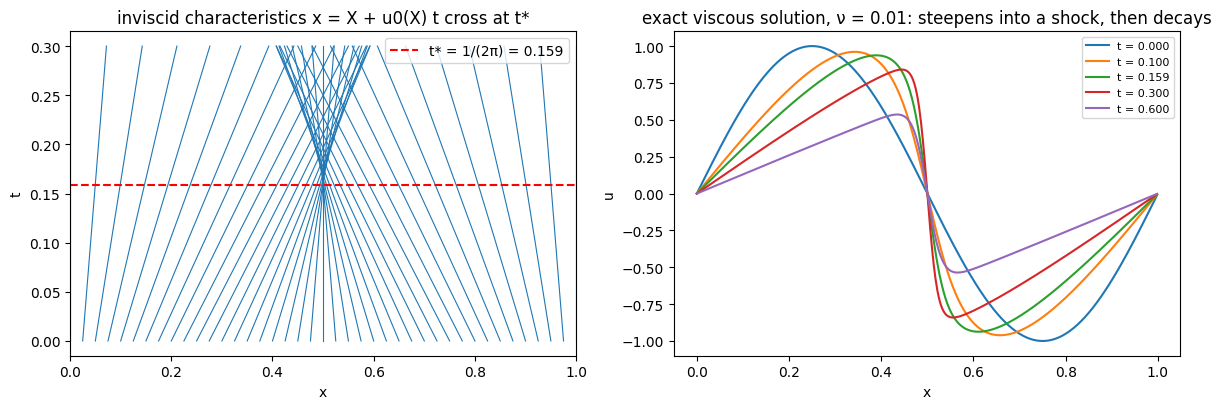

In [5]:
Xs, tl, xl = L.characteristics(n_lines=41, t_max=0.3)
xs = np.linspace(0, 1, 512, endpoint=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(xl, tl, "C0", lw=0.8); ax[0].axhline(ts, color="r", ls="--", label=f"t* = 1/(2π) = {ts:.3f}")
ax[0].set_xlim(0, 1); ax[0].set_xlabel("x"); ax[0].set_ylabel("t"); ax[0].legend()
ax[0].set_title("inviscid characteristics x = X + u0(X) t cross at t*")
for tt in (0, 0.1, ts, 0.3, 0.6):
    ax[1].plot(xs, L.cole_hopf_exact(xs, tt, 0.01), label=f"t = {tt:.3f}")
ax[1].set_xlabel("x"); ax[1].set_ylabel("u"); ax[1].legend(fontsize=8)
ax[1].set_title("exact viscous solution, ν = 0.01: steepens into a shock, then decays")
plt.tight_layout(); plt.show()

At the steepest point $X=\tfrac12$, $u_0' = -2\pi$, so the inviscid gradient is
$|u_x| = 2\pi/(1-2\pi t)$, which is infinite at $t^*$. With viscosity the exact Cole–Hopf solution
shows the gradient growing more slowly and peaking at a finite height. Smaller $\nu$ peaks later
(after $t^*$) and higher, with a peak that scales like $1/\nu$:

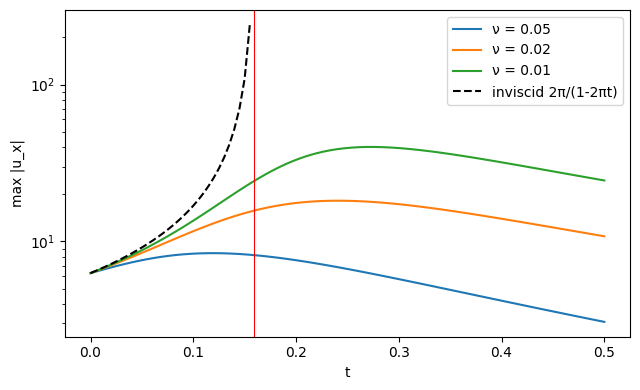

,nu,peak max|u_x|,peak * nu
0,0.05,8.422809,0.421140
1,0.02,18.196279,0.363926
2,0.01,40.066198,0.400662


In [6]:
tt = np.linspace(0.0, 0.5, 101)
xs = np.linspace(0, 1, 2048, endpoint=False)
plt.figure(figsize=(6.5, 4))
peaks = []
for v in (0.05, 0.02, 0.01):
    g = [np.max(np.abs(np.gradient(L.cole_hopf_exact(xs, s, v), xs[1]-xs[0]))) for s in tt]
    peaks.append((v, max(g), max(g)*v)); plt.semilogy(tt, g, label=f"ν = {v}")
ti = tt[tt < ts*0.98]; plt.semilogy(ti, 2*np.pi/(1-2*np.pi*ti), "k--", label="inviscid 2π/(1-2πt)")
plt.axvline(ts, color="r", lw=0.8); plt.xlabel("t"); plt.ylabel("max |u_x|"); plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame(peaks, columns=["nu", "peak max|u_x|", "peak * nu"])

`peak × ν` is roughly constant, so the peak gradient scales like $1/\nu$, exactly the Taylor-shock
estimate $U^2/(2\nu)$ with $U\approx1$ (the measured constant is a bit below ½ because $U$ has
already decayed below 1). The gradient is finite for every $\nu>0$ and infinite at $\nu=0$. This is
the 1D version of the question the Lean repository in the previous notebook formalizes for 3D.

# 4. Special relativity: the material derivative is $u^\mu\partial_\mu$

Relativity is already written in Lagrangian language. A particle's **worldline** is its Lagrangian
path, and its **proper time** $\tau$ is the clock it carries. With four-velocity
$u^\mu = \gamma(c, v)$ and $x^0 = ct$,
$$u^\mu\partial_\mu f = \gamma\,(\partial_t f + v\,\partial_x f) = \gamma\,\frac{Df}{Dt} = \frac{df}{d\tau}.$$
So the relativistic material derivative is the Newtonian one times $\gamma$.

**Dust.** For a pressureless relativistic fluid, $u^\mu\partial_\mu u^\nu = 0$ (each particle moves
freely). Since $\gamma v$ depends only on $v$, the spatial component becomes
$\gamma\,\frac{d(\gamma v)}{dv}\,(v_t + v v_x) = 0$, and $d(\gamma v)/dv = \gamma^3 > 0$. So
$$v_t + v\,v_x = 0 \quad\text{exactly, at any speed below } c.$$
Relativistic dust obeys inviscid Burgers: its worldlines are the straight characteristics of §3, and
they cross (caustics) at the same breaking time.

In [7]:
print("u^mu d_mu f - gamma Df/Dt =", L.four_velocity_derivative_check())
ratio, g3 = L.relativistic_dust_reduces_to_burgers()
print("[u^mu d_mu (gamma v)] / [gamma^4 (v_t + v v_x)] =", ratio, "   d(gamma v)/dv - gamma^3 =", g3)

u^mu d_mu f - gamma Df/Dt = 0
[u^mu d_mu (gamma v)] / [gamma^4 (v_t + v v_x)] = 1    d(gamma v)/dv - gamma^3 = 0


**Biology.** Tracking a cell is a Lagrangian measurement: you follow the particle. A fixed camera
pixel or PIV grid is Eulerian. The same $D/Dt$ converts between them. Relativity's correction to the
cell's own clock, $\gamma - 1$, is negligible at biological speeds:

In [8]:
speeds = {"cell crawling (1 um/s)": 1e-6, "capillary blood (0.5 mm/s)": 5e-4,
          "aortic blood (0.2 m/s)": 0.2, "flow cytometer (4 m/s)": 4.0, "GPS satellite (3.9 km/s)": 3.9e3}
pd.DataFrame({"speed (m/s)": list(speeds.values()),
              "gamma - 1": [f"{L.time_dilation_fraction(v):.2e}" for v in speeds.values()]}, index=list(speeds))

,speed (m/s),gamma - 1
cell crawling (1 um/s),0.000001,5.56e-30
capillary blood (0.5 mm/s),0.000500,1.39e-24
aortic blood (0.2 m/s),0.200000,2.23e-19
flow cytometer (4 m/s),4.000000,8.90e-17
GPS satellite (3.9 km/s),3900.000000,8.46e-11


A GPS satellite's $\gamma - 1 \approx 10^{-10}$ adds up to microseconds per day and must be corrected.
A cell in a flow cytometer is about $10^{-16}$, six orders of magnitude smaller. Relativity contributes the
*language* (worldlines, proper time, $u^\mu\partial_\mu$), not a measurable correction.

# 5. Light as a fluid: the "nature as a computer" idea

The Physics-AI Symbiosis paper [8] (§2) describes using a fast optical system as an analog proxy for
fluid dynamics: "A natural computer based on such rapid dynamics can be a proxy" for hydrodynamic
phenomena. The mathematics behind that claim is the **Madelung transform**. Take the nonlinear
Schrödinger equation, which describes pulse propagation in optical fiber:
$$i\psi_t = -\tfrac12\psi_{xx} + g|\psi|^2\psi ,$$
In fiber, $t$ is propagation distance $z$, $x$ is retarded time $\tau$, and $g>0$ is normal
dispersion (defocusing). Write $\psi = \sqrt{\rho}\,e^{iS}$ and define $u = S_x$. The real and
imaginary parts become
$$\rho_t + (\rho u)_x = 0,\qquad u_t + u\,u_x = -g\,\rho_x + \partial_x\!\left(\frac{(\sqrt\rho)_{xx}}{2\sqrt\rho}\right).$$
These are the continuity equation and Euler's momentum equation for a compressible fluid with pressure
$g\rho^2/2$, plus a dispersive "quantum pressure." When that last term is small, the left side is
Burgers again: intense pulses steepen and **break** (optical wave breaking, dispersive shock waves).
SymPy checks both equations:

In [9]:
cont, phase = L.madelung_check()
print("continuity  - 2A * Im(NLSE e^{-iS}) =", cont)
print("phase eq.   + Re(NLSE e^{-iS}) / A  =", phase)

continuity  - 2A * Im(NLSE e^{-iS}) = 0
phase eq.   + Re(NLSE e^{-iS}) / A  = 0


**Limits of the analogy.** The optical fluid is inviscid and dispersive. Its shocks are regularized by
the $(\sqrt\rho)_{xx}$ term (they oscillate) instead of by $\nu u_{xx}$ (which smooths). So fiber
optics is a fast proxy for *compressible Euler / shallow-water* dynamics, not for viscous
Navier–Stokes. That distinction matters when you read claims about optical "fluid computers.\"

# 6. Blood vs water: which terms of Navier–Stokes survive?

Two dimensionless numbers decide it:

* **Reynolds** $Re = U\,(2R)/\nu$: inertia vs viscosity. Steady pipe flow becomes turbulent around 2000.
* **Womersley** $\alpha = R\sqrt{\omega/\nu}$, with $\omega$ the heart's angular frequency:
  pulsation vs viscosity. For $\alpha\ll1$ the flow is quasi-steady Poiseuille. For $\alpha\gg1$ the
  core moves like a plug and viscosity only acts in a thin wall layer.

Blood's kinematic viscosity is about 3.3× that of water at 37 °C (high-shear value: blood is shear-thinning,
so this is a Newtonian approximation):

In [10]:
rows = []
for vessel, (R, U) in L.VESSELS.items():
    for fluid, nuf in L.FLUIDS.items():
        Re, a = L.reynolds_womersley(R, U, nuf)
        rows.append({"vessel": vessel, "fluid": fluid, "Re": round(Re, 3), "Womersley alpha": round(a, 3)})
df = pd.DataFrame(rows)
df.pivot(index="vessel", columns="fluid", values="Re").join(
    df.pivot(index="vessel", columns="fluid", values="Womersley alpha"), lsuffix=" | Re", rsuffix=" | alpha")

fluid,blood 37 C (high shear) | Re,water 20 C | Re,water 37 C | Re,blood 37 C (high shear) | alpha,water 20 C | alpha,water 37 C | alpha
vessel,,,,,,
aorta,1514.286,5000.000,7246.377,18.889,34.323,41.321
arteriole,0.076,0.250,0.362,0.038,0.069,0.083
capillary,0.001,0.004,0.006,0.006,0.011,0.013
femoral artery,242.286,800.000,1159.420,6.044,10.983,13.223


**Womersley's exact solution.** For an oscillating pressure gradient $-\partial_x p = A\cos\omega t$,
the axial velocity solves $i\alpha^2 w = 4 + w'' + w'/r$ (normalized), giving
$$\frac{u}{u_{\text{Pois}}} = \operatorname{Re}\left\{\frac{4}{i\alpha^2}\left[1 - \frac{J_0(i^{3/2}\alpha\, r/R)}{J_0(i^{3/2}\alpha)}\right]e^{i\omega t}\right\}.$$
Below we check the ODE residual and the $\alpha\to0$ Poiseuille limit, then plot the profiles.
Bessel functions with complex argument are the same ones as in the spherical-Bessel and waveguide notebooks.

ODE residual (alpha = 5, 15): 5.808306548263737e-06 4.1844109944191597e-05
alpha -> 0 limit: [1.   0.96 0.84 0.64 0.36 0.  ]  vs 1 - r^2: [1.   0.96 0.84 0.64 0.36 0.  ]


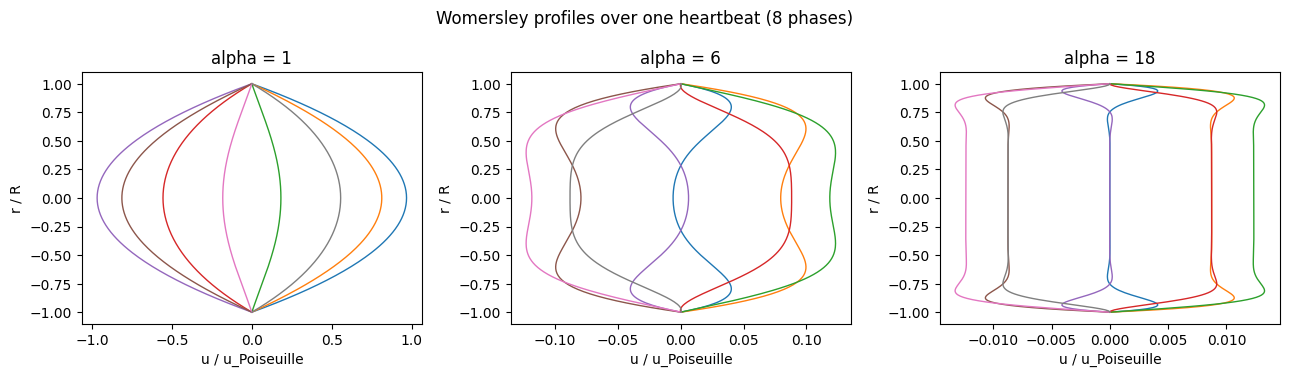

In [11]:
print("ODE residual (alpha = 5, 15):", L.womersley_ode_residual(5.0), L.womersley_ode_residual(15.0))
r = np.linspace(0, 1, 6)
print("alpha -> 0 limit:", np.round(L.womersley_profile(r, 0.02, 0.0), 5), " vs 1 - r^2:", np.round(1 - r**2, 5))
rr = np.linspace(-1, 1, 201)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for a_, alpha in zip(ax, (1.0, 6.0, 18.0)):
    for ph in np.linspace(0, 2*np.pi, 8, endpoint=False):
        a_.plot(L.womersley_profile(np.abs(rr), alpha, ph), rr, lw=1)
    a_.set_title(f"alpha = {alpha:g}"); a_.set_xlabel("u / u_Poiseuille"); a_.set_ylabel("r / R")
plt.suptitle("Womersley profiles over one heartbeat (8 phases)"); plt.tight_layout(); plt.show()

**Where the homogeneous-fluid assumption fails.** Navier–Stokes treats blood as a continuum. In a
capillary (radius about 4 µm) a red cell (about 8 µm across) fills the whole lumen and the cells move in
single file. Blood there is not a homogeneous fluid at all, and the apparent viscosity drops in narrow
tubes (the Fåhræus–Lindqvist effect). The table's capillary row is a scaling estimate, not a valid NS
prediction. Large arteries ($\alpha \approx 6$–$20$) are where Newtonian Womersley flow is a good model.

# 7. Respiratory droplets: Stokes settling

A droplet falling through still air reaches terminal speed when Stokes drag balances weight minus
buoyancy. Stokes drag $3\pi\mu d v$ is the exact low-$Re$ solution of Navier–Stokes around a sphere:

In [12]:
display(Math(r"v_s = " + sp.latex(L.stokes_drag_symbolic())))
d = np.array([1, 5, 10, 20, 50, 100]) * 1e-6
v, Re = L.stokes_settling(d)
pd.DataFrame({"diameter (um)": d*1e6, "v_s (m/s)": v, "particle Re": Re,
              "Stokes valid (Re<1)": Re < 1, "fall 1.5 m (min)": 1.5 / v / 60}).round(5)

<IPython.core.display.Math object>

,diameter (um),v_s (m/s),particle Re,Stokes valid (Re<1),fall 1.5 m (min)
0,1.0,0.00003,0.00000,True,831.27276
1,5.0,0.00075,0.00025,True,33.25091
2,10.0,0.00301,0.00199,True,8.31273
3,20.0,0.01203,0.01595,True,2.07818
4,50.0,0.07519,0.24924,True,0.33251
5,100.0,0.30074,1.99388,False,0.08313


Settling time scales as $1/d^2$. A 100 µm droplet falls 1.5 m in about 5 s, while a 1 µm one
takes about 14 hours, so in practice it moves with the room's air currents instead of settling. This
is the size split behind the droplet-vs-aerosol distinction that goes back to Wells [6].

The model leaves out several real effects:
- evaporation (droplets shrink as they fall, Wells' central point);
- the slip correction below about 1 µm;
- the breath jet;
- room ventilation and turbulence;
- the 100 µm case, where $Re\approx2$ and Stokes' law is already only approximate.

It is a fluid-mechanics exercise, not an exposure model.

# 8. One scheme, four implementations, one exact answer

All codes use the same discretization:
- conservative flux $-(u^2/2)_x$ and $\nu u_{xx}$ with second-order central differences;
- RK4 time stepping on a periodic grid;
- $u_0 = \sin 2\pi x$, solved to $t = 0.5$.

They are all compared with the exact Cole–Hopf solution from §2.

## 8.1 NumPy reference: second-order convergence

In [13]:
rows = []
for n in (64, 128, 256, 512):
    xg, u, steps = L.solve_burgers(n, 0.05, 0.5)
    rows.append({"N": n, "steps": steps, "max error": np.max(np.abs(u - L.cole_hopf_exact(xg, 0.5, 0.05)))})
conv = pd.DataFrame(rows); conv["ratio"] = conv["max error"].shift(1) / conv["max error"]
conv

,N,steps,max error,ratio
0,64,512,0.000536,NaN
1,128,2048,0.000134,4.004343
2,256,8192,0.000033,4.000882
3,512,32768,0.000008,3.999783


Halving $\Delta x$ cuts the error by about 4 = $2^2$, as a second-order scheme should.

## 8.2 torch on CUDA and CPU: when does the GPU win?

`dgs/torch/burgers_batched.py` advances $B$ independent problems as one $(B, N)$ tensor. The device
order is CUDA, then MPS (Apple Metal), then CPU. One RK4 step is about 40 small elementwise kernels, so
for small $B$ the GPU spends its time *launching* kernels, not computing:

In [14]:
import torch
from dgs.torch.burgers_batched import solve_batched, throughput, pick_device
print("torch", torch.__version__, "| default device:", pick_device())
nus = [0.05, 0.02, 0.01]
xg, U, steps, sec, dev = solve_batched(nus, n=256)      # N = 256 keeps this cell under a minute
print(f"{dev}: {len(nus)} viscosities, {steps} steps, {sec:.1f} s")
print("max error vs Cole-Hopf:", [f"{np.max(np.abs(U[i]-L.cole_hopf_exact(xg, 0.5, v))):.2e}" for i, v in enumerate(nus)])

torch 2.11.0+cu128 | default device: cuda


cuda: 3 viscosities, 8192 steps, 27.5 s
max error vs Cole-Hopf: ['3.34e-05', '1.09e-04', '5.09e-04']


In [15]:
devices = ["cpu"] + (["cuda"] if torch.cuda.is_available() else [])
rows = []
for B in (1, 16, 256, 4096):
    for dt_ in (torch.float64, torch.float32):
        row = {"batch B": B, "dtype": str(dt_).split(".")[1]}
        for d in devices:
            row[f"{d} updates/s"] = throughput(B, n_steps=100, device=torch.device(d), dtype=dt_)[1]
        rows.append(row)
bench = pd.DataFrame(rows)
if "cuda updates/s" in bench:
    bench["GPU speedup"] = bench["cuda updates/s"] / bench["cpu updates/s"]
bench.style.format({c: "{:.2e}" for c in bench.columns if "updates" in c} | {"GPU speedup": "{:.2f}"})

,batch B,dtype,cpu updates/s,cuda updates/s,GPU speedup
0,1,float64,2.67e+06,1.49e+05,0.06
1,1,float32,2.38e+06,1.53e+05,0.06
2,16,float64,2.20e+07,2.44e+06,0.11
3,16,float32,2.74e+07,2.45e+06,0.09
4,256,float64,3.52e+07,4.38e+07,1.24
5,256,float32,4.97e+07,5.35e+07,1.08
6,4096,float64,5.25e+07,1.72e+08,3.28
7,4096,float32,1.55e+08,4.91e+08,3.16


Read the table rather than assuming:

* For one problem the GPU is several times **slower** than the CPU, because launch overhead dominates.
* It breaks even at a few hundred problems and wins by about 2× at 4096.
* float64 costs only about 3× here, not the 1/64 FP64 compute rate of a GeForce card. A stencil is
  memory-bound, so the arithmetic penalty mostly hides behind memory traffic.

The lesson for a real instrument: batch the work, or fuse the kernels (next section).

## 8.3 CUDA C: fused kernels

[`hardware/cuda_burgers/burgers.cu`](../hardware/cuda_burgers/burgers.cu) does each RK4 stage in **one** kernel
(right-hand side, stage update and accumulator together), so a time step is 4 launches instead of about 40.
Build it from an x64 Native Tools prompt with `nvcc -O2 -o burgers.exe burgers.cu`. The cell runs it
if the executable is present:

In [16]:
cu = ROOT / "hardware" / "cuda_burgers"
exe = cu / "burgers.exe"
if exe.exists():
    for args in (["5", "512", "0.5"], ["4096", "512", "0.5", "100"]):
        print(subprocess.run([str(exe), *args], capture_output=True, text=True, cwd=str(cu)).stdout.strip())
    data = np.loadtxt(cu / "burgers_out.csv", delimiter=",", skiprows=1)
    print("CUDA max error vs Cole-Hopf: nu=0.01 %.3e, nu=0.05 %.3e" % (
        np.max(np.abs(data[:, 1] - L.cole_hopf_exact(data[:, 0], 0.5, 0.01))),
        np.max(np.abs(data[:, 2] - L.cole_hopf_exact(data[:, 0], 0.5, 0.05)))))
else:
    print("burgers.exe not built; see the build line above.")

B=5 N=512 steps=32768 dt=1.525879e-05 seconds=1.2566 updates_per_s=6.676e+07
wrote burgers_out.csv


B=4096 N=512 steps=100 dt=1.525879e-05 seconds=0.3517 updates_per_s=5.963e+08
CUDA max error vs Cole-Hopf: nu=0.01 1.278e-04, nu=0.05 8.361e-06


Compare the B = 4096 float64 throughput with the torch CUDA row above. The same arithmetic, fused
into 4 launches per step, runs about 4× faster than torch's many small kernels, and gives the same
error to every printed digit.

## 8.4 MATLAB

[`learn/matlab/burgers_cole_hopf.m`](../learn/matlab/burgers_cole_hopf.m) is the same scheme, using
vectorized `circshift` for the periodic stencil. Run it with
`matlab -batch "run('learn/matlab/burgers_cole_hopf.m')"`. It writes a CSV that we compare here:

In [17]:
mcsv = ROOT / "learn" / "matlab" / "burgers_matlab.csv"
if mcsv.exists():
    m = np.loadtxt(mcsv, delimiter=",")
    xr, ur, _ = L.solve_burgers(512, 0.01, 0.5)
    print("MATLAB FD vs exact:      %.3e" % np.max(np.abs(m[:, 1] - m[:, 2])))
    print("MATLAB exact vs Python:  %.3e" % np.max(np.abs(m[:, 2] - L.cole_hopf_exact(m[:, 0], 0.5, 0.01))))
    print("MATLAB FD vs Python FD:  %.3e" % np.max(np.abs(m[:, 1] - ur)))
else:
    print("burgers_matlab.csv not found; run the MATLAB script first.")

MATLAB FD vs exact:      1.278e-04
MATLAB exact vs Python:  3.255e-13
MATLAB FD vs Python FD:  4.996e-16


## 8.5 Metal

Apple's GPUs are reached from Python through torch's `mps` device. `pick_device()` selects it
automatically, and the solver switches to float32 because MPS has no float64. That path has **not**
been run: this is a Windows/NVIDIA machine. A native Metal Shading Language kernel would mirror
`burgers.cu` line for line (one thread per grid point, the same fused stage), but it can only be
compiled and tested on a Mac.

# Summary

| claim | how it was checked | result |
|---|---|---|
| NS momentum = Griffiths-style conservation law | SymPy identity | 0 |
| Cole–Hopf maps Burgers to $\varphi_t=\nu\varphi_{xx}$ | SymPy, arbitrary $\varphi$ | 0 |
| inviscid gradient blows up at $t^*=1/(2\pi)$ | SymPy + characteristics | ✓ |
| viscous peak gradient $\propto 1/\nu$ | exact solution | peak·ν ≈ const |
| $u^\mu\partial_\mu = \gamma D/Dt$; dust obeys Burgers | SymPy | 0 |
| NLSE = compressible Euler + quantum pressure | SymPy | 0 |
| Womersley solves the pulsatile pipe ODE; α→0 gives Poiseuille | finite differences | ✓ |
| four codes agree with each other and with the exact solution | max error | identical to roundoff |

## Exercises
1. Redo §2 by hand for $u_0 = -\tanh(x/(2\nu))$ and show that $\varphi_0$ is a sum of two exponentials, so the shock is two heat-equation modes.
2. Find $t^*$ for $u_0 = e^{-x^2}$ (where is $u_0'$ most negative?).
3. Use the Womersley table to explain why a pulse oximeter or Doppler probe sees a flat (plug) profile in the aorta.
4. In §8.2, predict from the table the batch size where float32 CUDA first beats float32 CPU, then measure it.
5. Write the Madelung equations for $g<0$ (anomalous dispersion). What changes sign, and why does that lead to modulation instability instead of wave breaking?